In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score

df = pd.read_csv("../data/raw/fraud_oracle.csv")

X = df.drop(columns=[
    "FraudFound_P",
    "PolicyNumber",
    "RepNumber"
])

y = df["FraudFound_P"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train = X_train.copy()
X_train["Age"] = X_train["Age"].replace(0, np.nan)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (12336, 30)
Testing shape: (3084, 30)


In [2]:
categorical_features = X_train.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

categorical_features += ["Year", "DriverRating"]

numerical_features = [
    col for col in X_train.select_dtypes(include="number").columns
    if col not in categorical_features
]

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

cluster_preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

X_cluster = cluster_preprocessor.fit_transform(X_train)

print("Clustering data shape:", X_cluster.shape)

Clustering data shape: (12336, 151)


Number of records in each cluster:
Cluster
0    4052
1    4785
2    3499
Name: count, dtype: int64


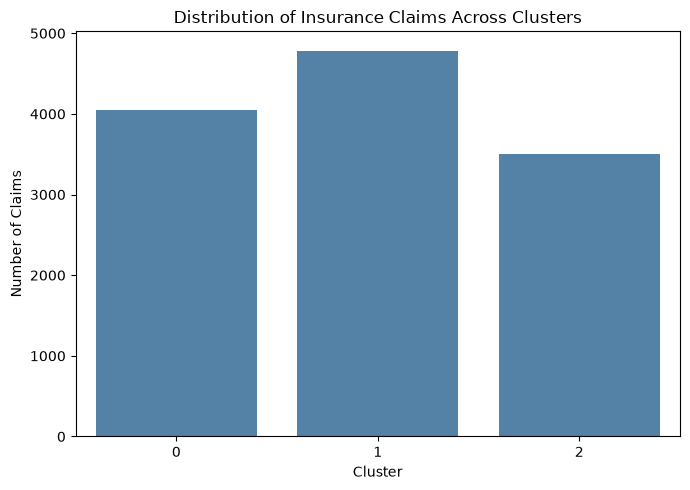

In [3]:
kmeans = MiniBatchKMeans(
    n_clusters=3,
    random_state=42,
    batch_size=1024,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X_cluster)

cluster_counts = pd.Series(
    cluster_labels,
    name="Cluster"
).value_counts().sort_index()

print("Number of records in each cluster:")
print(cluster_counts)

plt.figure(figsize=(7, 5))

sns.barplot(
    x=cluster_counts.index.astype(str),
    y=cluster_counts.values,
    color="steelblue"
)

plt.title("Distribution of Insurance Claims Across Clusters")
plt.xlabel("Cluster")
plt.ylabel("Number of Claims")
plt.tight_layout()
plt.show()

In [4]:
silhouette = silhouette_score(
    X_cluster,
    cluster_labels,
    sample_size=2000,
    random_state=42
)

print(f"Silhouette Score: {silhouette:.4f}")

Silhouette Score: 0.0402


In [5]:
cluster_results = []

for k in range(2, 7):
    model = MiniBatchKMeans(
        n_clusters=k,
        random_state=42,
        batch_size=1024,
        n_init=10
    )

    labels = model.fit_predict(X_cluster)

    score = silhouette_score(
        X_cluster,
        labels,
        sample_size=2000,
        random_state=42
    )

    cluster_results.append({
        "Clusters": k,
        "Silhouette Score": score,
        "Inertia": model.inertia_
    })

cluster_results_df = pd.DataFrame(cluster_results)

display(cluster_results_df.round(4))

,Clusters,Silhouette Score,Inertia
0,2,0.0739,194457.7559
1,3,0.0402,190647.9002
2,4,0.0517,180024.8080
3,5,0.0554,175800.1350
4,6,0.0490,172757.5651


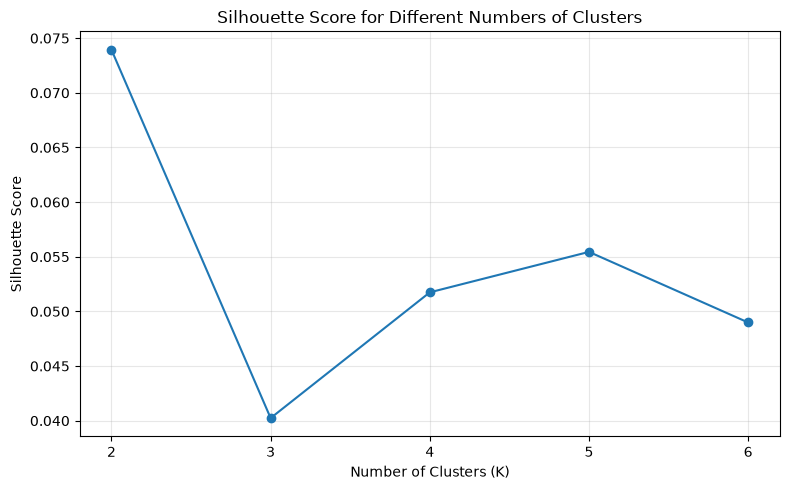

In [6]:
plt.figure(figsize=(8, 5))

plt.plot(
    cluster_results_df["Clusters"],
    cluster_results_df["Silhouette Score"],
    marker="o"
)

plt.title("Silhouette Score for Different Numbers of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(cluster_results_df["Clusters"])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
best_kmeans = MiniBatchKMeans(
    n_clusters=2,
    random_state=42,
    batch_size=1024,
    n_init=10
)

best_cluster_labels = best_kmeans.fit_predict(X_cluster)

cluster_analysis = pd.DataFrame({
    "Cluster": best_cluster_labels,
    "Fraud": y_train.to_numpy()
})

cluster_summary = (
    cluster_analysis.groupby("Cluster")["Fraud"]
    .agg(["count", "sum", "mean"])
)

cluster_summary.columns = [
    "Total Claims",
    "Fraud Claims",
    "Fraud Rate"
]

cluster_summary["Fraud Rate (%)"] = (
    cluster_summary["Fraud Rate"] * 100
)

display(cluster_summary.round(2))

,Total Claims,Fraud Claims,Fraud Rate,Fraud Rate (%)
Cluster,,,,
0,4240,239,0.06,5.64
1,8096,499,0.06,6.16


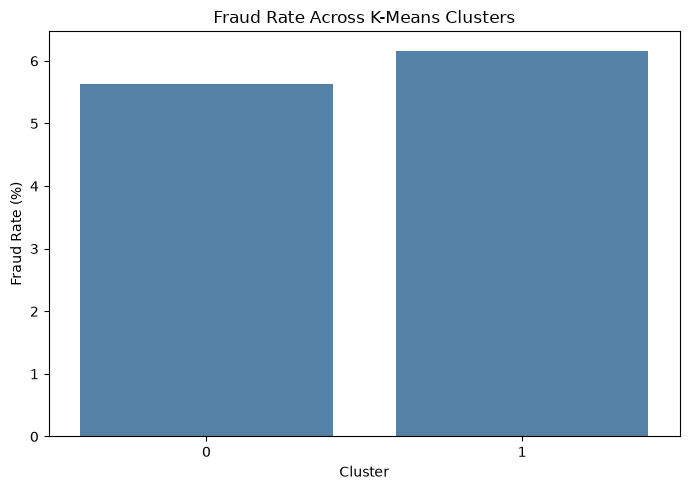

In [8]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=cluster_summary.index.astype(str),
    y=cluster_summary["Fraud Rate (%)"],
    color="steelblue"
)

plt.title("Fraud Rate Across K-Means Clusters")
plt.xlabel("Cluster")
plt.ylabel("Fraud Rate (%)")
plt.tight_layout()
plt.show()

In [9]:
from sklearn.ensemble import RandomForestClassifier

feature_rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

feature_rf.fit(X_cluster, y_train)

feature_names = cluster_preprocessor.get_feature_names_out()

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_rf.feature_importances_
}).sort_values("Importance", ascending=False)

display(feature_importance_df.head(15))

,Feature,Importance
72,cat__Fault_Third Party,0.133285
71,cat__Fault_Policy Holder,0.113594
143,cat__BasePolicy_Liability,0.094068
75,cat__PolicyType_Sedan - Liability,0.069116
83,cat__VehicleCategory_Sport,0.054889
82,cat__VehicleCategory_Sedan,0.038912
141,cat__BasePolicy_All Perils,0.027007
132,cat__AddressChange_Claim_2 to 3 years,0.025759
142,cat__BasePolicy_Collision,0.024203
2,num__Age,0.022737


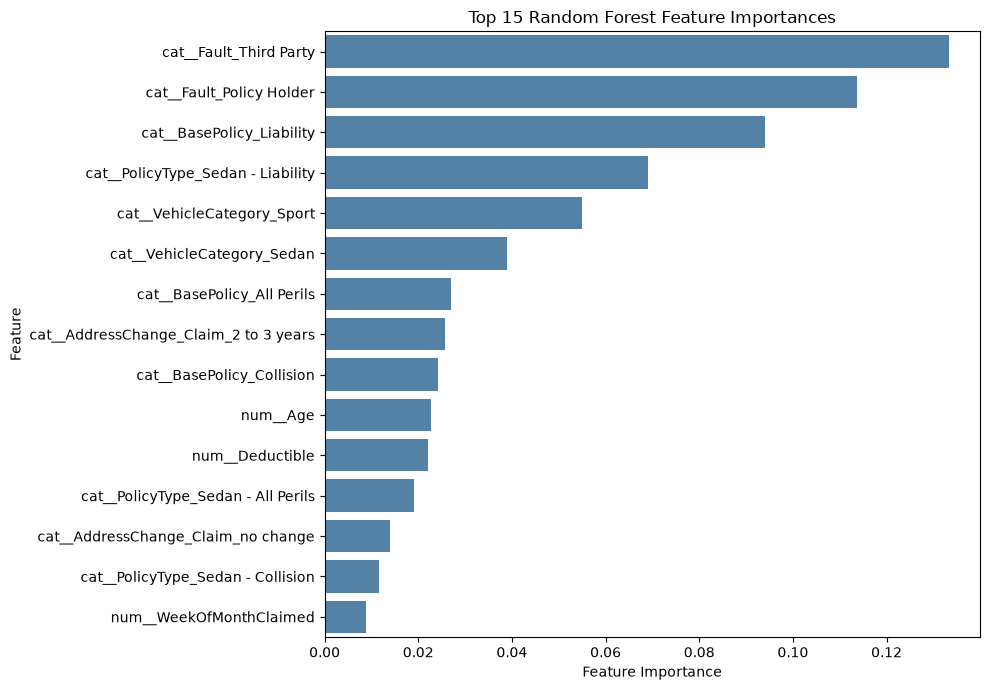

In [10]:
top_features = feature_importance_df.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature",
    color="steelblue"
)

plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [11]:
from sklearn.feature_selection import SelectFromModel
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

selection_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

selected_rf = Pipeline([
    ("preprocessor", clone(cluster_preprocessor)),
    ("selector", SelectFromModel(
        estimator=selection_model,
        threshold="median"
    )),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

selection_scores = cross_validate(
    selected_rf,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "f1": "f1",
        "average_precision": "average_precision"
    },
    n_jobs=1
)

print("Random Forest with feature selection")

for metric in ["f1", "average_precision"]:
    values = selection_scores[f"test_{metric}"]
    print(f"{metric}: {values.mean():.4f} (+/- {values.std():.4f})")

Random Forest with feature selection
f1: 0.2429 (+/- 0.0054)
average_precision: 0.2043 (+/- 0.0272)


In [12]:
full_rf = Pipeline([
    ("preprocessor", clone(cluster_preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

full_scores = cross_validate(
    full_rf,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "f1": "f1",
        "average_precision": "average_precision"
    },
    n_jobs=1
)

print("Random Forest without feature selection")

for metric in ["f1", "average_precision"]:
    values = full_scores[f"test_{metric}"]
    print(f"{metric}: {values.mean():.4f} (+/- {values.std():.4f})")

Random Forest without feature selection
f1: 0.2400 (+/- 0.0059)
average_precision: 0.2191 (+/- 0.0264)
